# Exploratory Data Analysis: Hotel Booking No-Shows (Classification)

## Objective
Each row is one hotel booking, identified by `booking_id`. The goal is to **predict `no_show`**: whether the guest fails to turn up (1) or arrives (0). This is a **binary classification** problem with **no-show (1) as the positive class**.

Candidate features: `branch`, `booking_month`, `arrival_month`, `arrival_day`, `checkout_month`, `checkout_day`, `country`, `first_time`, `room`, `price`, `platform`, `num_adults`, `num_children`.

## 1. Load the data

**What:** Import the analysis libraries and load `mini_project_2_data.csv` into a DataFrame.

**Why:** Everything that follows works on this DataFrame, `df`.

In [238]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('./data/mini_project_2_data.csv')
df.head()

,booking_id,no_show,branch,booking_month,arrival_month,arrival_day,checkout_month,checkout_day,country,first_time,room,price,platform,num_adults,num_children
0,94113,0.0,Changi,November,June,25.0,June,27.0,Singapore,Yes,Single,SGD$ 492.98,Website,1,0.0
1,86543,0.0,Orchard,August,November,28.0,November,29.0,Indonesia,Yes,King,SGD$ 1351.22,Website,2,0.0
2,75928,0.0,Changi,March,February,7.0,February,11.0,India,Yes,Single,NaN,Agent,1,0.0
3,66947,1.0,Orchard,September,October,1.0,October,3.0,China,Yes,Single,SGD$ 666.04,Website,1,0.0
4,106390,0.0,Orchard,March,June,20.0,June,24.0,Australia,Yes,Queen,USD$ 665.37,Website,1,0.0


## 2. Overview

**What:** Check the size of the dataset, the type of each column and a few sample rows.

**Why:** The data types show which columns need converting before modelling (e.g. numbers stored as text).

In [239]:
print(df.shape)
df.info()

(119391, 15)
<class 'pandas.DataFrame'>
RangeIndex: 119391 entries, 0 to 119390
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   booking_id      119391 non-null  int64  
 1   no_show         119390 non-null  float64
 2   branch          119390 non-null  str    
 3   booking_month   119390 non-null  str    
 4   arrival_month   119390 non-null  str    
 5   arrival_day     119390 non-null  float64
 6   checkout_month  119390 non-null  str    
 7   checkout_day    119390 non-null  float64
 8   country         119390 non-null  str    
 9   first_time      119390 non-null  str    
 10  room            97778 non-null   str    
 11  price           94509 non-null   str    
 12  platform        119390 non-null  str    
 13  num_adults      119390 non-null  str    
 14  num_children    119390 non-null  float64
dtypes: float64(4), int64(1), str(10)
memory usage: 13.7 MB


## 3. Duplicates

**What:** Check whether any `booking_id` appears more than once, and whether any rows are exact copies.

**Why:** Duplicate bookings would be counted twice in training, and could leak between the train and test splits.

In [240]:
print('Duplicate booking_id:', df['booking_id'].duplicated().sum())
print('Fully duplicated rows:', df.duplicated().sum())

Duplicate booking_id: 0
Fully duplicated rows: 0


## 4. Missing values

**What:** Count the nulls in each column, as a number and as a percentage of rows.

**Why:** How we handle missing values (drop, fill, or flag) depends on how many there are and whether they are linked to the target.

In [241]:
missing = df.isna().sum()
missing_table = pd.DataFrame({'n_missing': missing, 'pct_missing': (missing / len(df) * 100).round(2)})
missing_table[missing_table['n_missing'] > 0].sort_values('n_missing', ascending=False)

,n_missing,pct_missing
price,24882,20.84
room,21613,18.10
booking_month,1,0.00
arrival_month,1,0.00
no_show,1,0.00
branch,1,0.00
checkout_month,1,0.00
arrival_day,1,0.00
country,1,0.00
checkout_day,1,0.00


Every column except `booking_id` has exactly one null. Check whether they all come from the same row.

In [242]:
empty_rows = df[df.drop(columns='booking_id').isna().all(axis=1)]
empty_rows

,booking_id,no_show,branch,booking_month,arrival_month,arrival_day,checkout_month,checkout_day,country,first_time,room,price,platform,num_adults,num_children
111598,115536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**What:** Check whether `room` and `price` go missing together, and whether the no-show rate differs between rows with and without them.

**Why:** If missingness is linked to the target, the fact that a value is missing is itself informative and should be kept (e.g. as a flag), not just filled in.

In [243]:
df_valid = df.dropna(subset=['no_show'])
print('room and price both missing:', (df_valid['room'].isna() & df_valid['price'].isna()).sum())

pd.DataFrame({
    col: df_valid.groupby(df_valid[col].isna())['no_show'].mean()
    for col in ['room', 'price']
}).rename(index={False: 'present', True: 'missing'}).round(3)

room and price both missing: 0


,room,price
present,0.371,0.370
missing,0.368,0.372


### Summary of missing values

| Column | Missing | % | Notes |
|---|---|---|---|
| all except `booking_id` | 1 | 0.00% | One completely empty row (`booking_id` 115536) |
| `room` | 21,612 | 18.1% | Excluding the empty row |
| `price` | 24,881 | 20.8% | Excluding the empty row |

- `room` and `price` are never missing in the same row.
- The no-show rate is about 37% whether `room` / `price` is missing or present, so missingness does not appear to be linked to the target.

**Decisions:**
- **Empty row:** drop it. It carries no information, and losing one row out of 119,391 has no effect.
- **`room` / `price`:** to be decided after the analysis in §4.1 below.

In [244]:
df = df.dropna(subset=['no_show']).reset_index(drop=True)
print(df.shape)

(119390, 15)


### 4.1 Room categories and price

**What:** List the room categories and their average price, so we can decide how to fill the missing `room` and `price` values.

**Why:** If price depends strongly on room type, each column can help fill the other: a missing price can be estimated from the room, and a missing room can be inferred from the price.

`price` is stored as text with a currency prefix (`SGD$ 492.98` or `USD$ 361.00`), so first split it into currency and amount.

In [245]:
price_parts = df['price'].str.extract(r'^(?P<currency>SGD|USD)\$\s*(?P<amount>[\d.]+)$')
price_parts['amount'] = price_parts['amount'].astype(float)
print('Unparsed non-null prices:', (df['price'].notna() & price_parts['amount'].isna()).sum())
price_parts['currency'].value_counts(dropna=False)

Unparsed non-null prices: 0


currency
SGD    47295
USD    47214
NaN    24881
Name: count, dtype: int64

**What:** Compare each room's SGD and USD prices.

**Why:** Averaging SGD and USD amounts together would be meaningless. If the two currencies differ by a constant factor, that factor is the exchange rate used to build the data, and we can convert everything to SGD.

In [246]:
by_currency = (
    pd.concat([df['room'], price_parts], axis=1)
    .groupby(['room', 'currency'])['amount'].agg(['min', 'max'])
    .unstack('currency')
)
by_currency['min_ratio'] = by_currency[('min', 'SGD')] / by_currency[('min', 'USD')]
by_currency['max_ratio'] = by_currency[('max', 'SGD')] / by_currency[('max', 'USD')]
by_currency.round(2)

min              max          min_ratio max_ratio
currency             SGD     USD      SGD      USD                    
room                                                                  
King              800.03  584.01  1499.96  1094.95      1.37      1.37
President Suite  1254.58  886.43  2099.96  1530.06      1.42      1.37
Queen             600.15  438.13  1199.75   875.96      1.37      1.37
Single            400.00  292.01   899.77   656.96      1.37      1.37

The SGD / USD ratio is about **1.37** for every room type, so USD prices are SGD prices divided by 1.37. Convert all prices to SGD.

In [247]:
USD_TO_SGD = 1.37
df['price_sgd'] = price_parts['amount'].where(price_parts['currency'] == 'SGD', price_parts['amount'] * USD_TO_SGD)

room_order = ['Single', 'Queen', 'King', 'President Suite']
room_price = df.groupby(df['room'].fillna('(missing)'))['price_sgd'].agg(['count', 'mean', 'median', 'min', 'max'])
room_price.loc[room_order + ['(missing)']].round(0)

,count,mean,median,min,max
room,,,,,
Single,11726,596.0,563.0,400.0,900.0
Queen,8041,919.0,963.0,600.0,1200.0
King,52578,1022.0,937.0,800.0,1500.0
President Suite,552,1936.0,1945.0,1214.0,2100.0
(missing),21612,950.0,913.0,400.0,2100.0


**What:** Break the room prices down by branch.

**Why:** The price ranges above are wide and overlap between rooms. Checking whether the two branches price rooms differently shows whether that spread comes from location rather than from the room itself.

In [248]:
room_branch_price = df.groupby([df['room'].fillna('(missing)'), 'branch'])['price_sgd'].agg(['count', 'mean', 'min', 'max'])
room_branch_price.loc[room_order + ['(missing)']].round(0)

count    mean     min     max
room            branch                                
Single          Changi    7209   500.0   400.0   600.0
                Orchard   4517   750.0   600.0   900.0
Queen           Changi    3019   698.0   600.0   800.0
                Orchard   5022  1052.0   900.0  1200.0
King            Changi   38376   900.0   800.0  1000.0
                Orchard  14202  1350.0  1200.0  1500.0
President Suite Changi      11  1262.0  1214.0  1374.0
                Orchard    541  1949.0  1800.0  2100.0
(missing)       Changi   14345   828.0   400.0  1352.0
                Orchard   7267  1192.0   600.0  2100.0

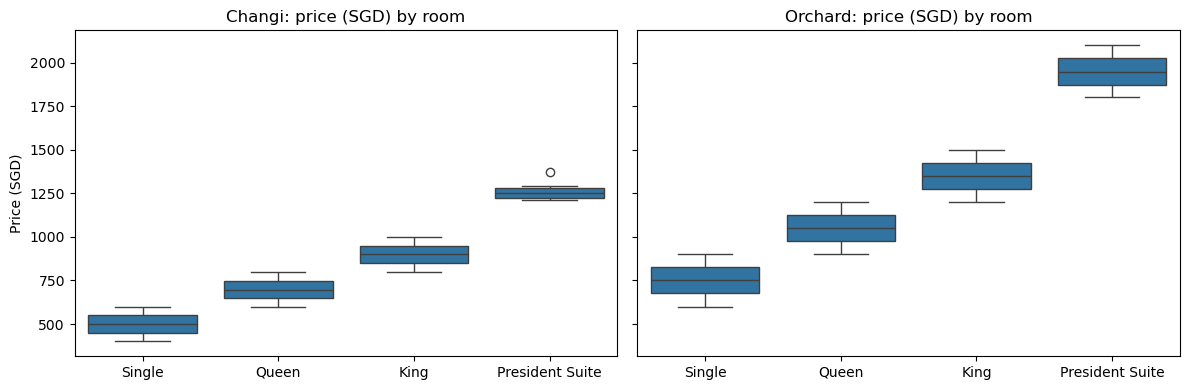

In [249]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, branch in zip(axes, ['Changi', 'Orchard']):
    subset = df[(df['branch'] == branch) & df['room'].notna()]
    sns.boxplot(data=subset, x='room', y='price_sgd', order=room_order, ax=ax)
    ax.set_title(f'{branch}: price (SGD) by room')
    ax.set_xlabel('')
axes[0].set_ylabel('Price (SGD)')
plt.tight_layout()
plt.show()

### Findings: room and price

- **4 room categories:** King (most common), Single, Queen, President Suite (rare).
- **Price is set by room *and* branch.** In SGD, each room/branch combination has its own fixed price band, and Orchard costs 1.5× Changi:

  | Room | Changi (SGD) | Orchard (SGD) |
  |---|---|---|
  | Single | 400–600 (avg 500) | 600–900 (avg 750) |
  | Queen | 600–800 (avg 700) | 900–1,200 (avg 1,050) |
  | King | 800–1,000 (avg 900) | 1,200–1,500 (avg 1,350) |
  | President Suite | ~1,200–1,400 (avg 1,260, only 11 bookings) | 1,800–2,100 (avg 1,950) |

- Within a branch, the bands barely overlap. The rows with a missing room have prices that fall inside these bands.

**Implications for filling:**
- **Missing `price`** (room known): fill with the median price for that room and branch.
- **Missing `room`** (price known): the room can likely be inferred from the price band for its branch, rather than filled with a generic `"Unknown"`.
- `room` and `price` are never missing together, so one of the two is always available.

**Decisions:**
- **Missing `price`:** fill with the median SGD price for the same room and branch (§4.2).
- **Missing `room`:** infer it from the room/branch price band the price falls in (§4.3).

### 4.2 Fill missing price

**What:** Fill each missing `price_sgd` with the median SGD price of bookings with the same `room` and `branch`.

**Why:** Price is set by room and branch (§4.1), so the median of that group is the best estimate for a missing price. The median is used rather than the mean because it is less affected by outliers. Rows with a missing price always have a known room, so every missing price has a group to take its median from.

In [250]:
room_branch_median = df.groupby(['room', 'branch'])['price_sgd'].transform('median')
price_was_missing = df['price_sgd'].isna()
df['price_sgd'] = df['price_sgd'].fillna(room_branch_median)

print('Prices filled:', price_was_missing.sum())
print('Missing price_sgd remaining:', df['price_sgd'].isna().sum())

Prices filled: 24881
Missing price_sgd remaining: 0


**What:** Check that filling did not change each group's price distribution.

**Why:** The fill should only add values at the centre of each band. The mean and median per room and branch should barely move, and min / max should stay the same.

In [251]:
before = df[~price_was_missing].groupby(['room', 'branch'])['price_sgd'].agg(['mean', 'median'])
after = df[df['room'].notna()].groupby(['room', 'branch'])['price_sgd'].agg(['count', 'mean', 'median', 'min', 'max'])
after.join(before, rsuffix='_before').loc[room_order].round(0)

count    mean  median     min     max  mean_before  \
room            branch                                                        
Single          Changi    9600   500.0   500.0   400.0   600.0        500.0   
                Orchard   6097   750.0   750.0   600.0   900.0        750.0   
Queen           Changi    4048   698.0   697.0   600.0   800.0        698.0   
                Orchard   6776  1051.0  1050.0   900.0  1200.0       1052.0   
King            Changi   51324   900.0   900.0   800.0  1000.0        900.0   
                Orchard  19172  1350.0  1351.0  1200.0  1500.0       1350.0   
President Suite Changi      13  1261.0  1255.0  1214.0  1374.0       1262.0   
                Orchard    748  1949.0  1948.0  1800.0  2100.0       1949.0   

                         median_before  
room            branch                  
Single          Changi           500.0  
                Orchard          750.0  
Queen           Changi           697.0  
                Orchard         1050.0  
King            Changi           900.0  
                Orchard         1351.0  
President Suite Changi          1255.0  
                Orchard         1948.0

### 4.3 Fill missing room

**What:** Infer each missing `room` from the price band its `price_sgd` falls into, within its branch.

**Why:** Within a branch, each room type has its own price band, and the bands follow each other in order: Single < Queen < King < President Suite (§4.1). Every booking with a missing room has a price, so the band tells us which room it most likely is.

**How:** For each branch, sort the room bands by price and place a cut point halfway between the top of one band and the bottom of the next. A price below the first cut point is a Single, between the first and second a Queen, and so on. Halfway points also cover the gap between King and President Suite (e.g. Changi 1,000–1,214), and the tiny overlaps at the band edges caused by rounding in the USD → SGD conversion.

In [252]:
known_room = df[df['room'].notna() & ~price_was_missing]  # bands from real prices only, not the filled medians
bands = known_room.groupby(['branch', 'room'])['price_sgd'].agg(['min', 'max']).sort_values(['branch', 'min'])

cut_points = {}
for branch, branch_bands in bands.groupby(level='branch'):
    branch_bands = branch_bands.droplevel('branch')
    edges = (branch_bands['max'].values[:-1] + branch_bands['min'].values[1:]) / 2
    cut_points[branch] = {'rooms': list(branch_bands.index), 'edges': [float('-inf'), *edges, float('inf')]}

bands.join(
    pd.DataFrame([
        {'branch': branch, 'room': room, 'assigned_from': cuts['edges'][k], 'assigned_to': cuts['edges'][k + 1]}
        for branch, cuts in cut_points.items() for k, room in enumerate(cuts['rooms'])
    ]).set_index(['branch', 'room'])
).round(2)

min      max  assigned_from  assigned_to
branch  room                                                         
Changi  Single            400.00   600.01           -inf       600.08
        Queen             600.15   800.07         600.08       800.05
        King              800.03  1000.09         800.05      1107.25
        President Suite  1214.41  1373.78        1107.25          inf
Orchard Single            600.22   900.04           -inf       900.11
        Queen             900.19  1200.07         900.11      1200.05
        King             1200.03  1500.08        1200.05      1650.18
        President Suite  1800.28  2099.96        1650.18          inf

In [253]:
def infer_room(prices: pd.Series, branches: pd.Series) -> pd.Series:
    """Maps each price to the room whose band it falls in, using that branch's cut points."""
    rooms = pd.Series(index=prices.index, dtype=object)
    for branch, cuts in cut_points.items():
        in_branch = branches == branch
        rooms[in_branch] = pd.cut(prices[in_branch], bins=cuts['edges'], labels=cuts['rooms']).astype(object)
    return rooms

**What:** Test the rule on bookings whose room is already known.

**Why:** If the rule recovers the true room for nearly all known bookings, we can trust it for the missing ones.

In [254]:
predicted = infer_room(known_room['price_sgd'], known_room['branch'])
print(f"Agreement with the known room: {(predicted == known_room['room']).mean():.4%}")
pd.crosstab(known_room['room'], predicted, rownames=['actual'], colnames=['inferred']).loc[room_order, room_order]

Agreement with the known room: 99.9877%


inferred,Single,Queen,King,President Suite
actual,,,,
Single,11726,0,0,0
Queen,0,8038,3,0
King,0,6,52572,0
President Suite,0,0,0,552


**What:** Fill the missing rooms and compare the room mix before and after.

In [255]:
room_was_missing = df['room'].isna()
df.loc[room_was_missing, 'room'] = infer_room(df.loc[room_was_missing, 'price_sgd'], df.loc[room_was_missing, 'branch'])
print('Rooms filled:', room_was_missing.sum())
print('Missing room remaining:', df['room'].isna().sum())

pd.DataFrame({
    'known_rooms_pct': (df.loc[~room_was_missing, 'room'].value_counts(normalize=True) * 100),
    'inferred_rooms_pct': (df.loc[room_was_missing, 'room'].value_counts(normalize=True) * 100),
    'inferred_count': df.loc[room_was_missing, 'room'].value_counts(),
}).loc[room_order].round(2)

Rooms filled: 21612
Missing room remaining: 0


,known_rooms_pct,inferred_rooms_pct,inferred_count
room,,,
Single,16.05,16.22,3505
Queen,11.07,11.28,2437
King,72.10,71.71,15499
President Suite,0.78,0.79,171


### Findings: room fill

- The price-band rule recovers the true room for **99.99%** of bookings whose room is known (9 of 72,897 wrong, all Queen ↔ King right at the 800 / 1,200 SGD edges).
- All **21,612** missing rooms are filled. The inferred mix (Single 16%, Queen 11%, King 72%, President Suite 0.8%) matches the known rooms almost exactly, which supports the missing rooms being a random sample of all bookings.
- `room` and `price_sgd` now have no missing values.

> **Note for the pipeline:** in this EDA the room/branch medians (§4.2) and price-band cut points (§4.3) are computed on the full dataset. In `src/data_preparation.py` they must be learned from the **training split only** and then applied to the validation and test splits, to avoid leaking information from the evaluation data.

## 5. Target variable: `no_show`

**What:** Count how many bookings fall into each class (excluding the empty row).

**Why:** In classification, the first thing to check is **class balance**. It decides which metrics are meaningful, how to split the data, and whether the models need class weighting.

In [256]:
target_counts = df_valid['no_show'].value_counts().sort_index()
target_pct = df_valid['no_show'].value_counts(normalize=True).sort_index() * 100
pd.DataFrame({'count': target_counts, 'pct': target_pct.round(2)}).rename(index={0.0: 'Show (0)', 1.0: 'No-show (1)'})

,count,pct
no_show,,
Show (0),75166,62.96
No-show (1),44224,37.04


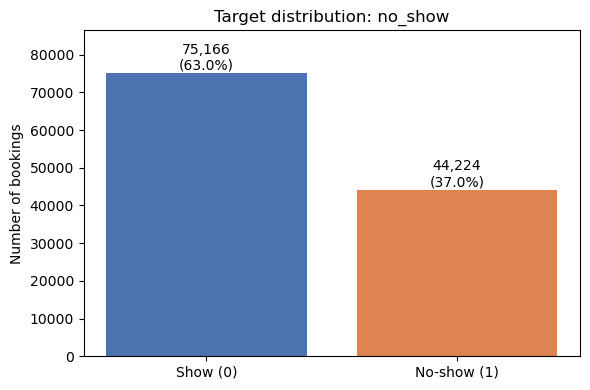

Imbalance ratio (show : no-show) = 1.70 : 1


In [257]:
fig, ax = plt.subplots(figsize=(6, 4))
labels = ['Show (0)', 'No-show (1)']
bars = ax.bar(labels, target_counts.values, color=['#4C72B0', '#DD8452'])
for bar, pct in zip(bars, target_pct.values):
    ax.annotate(f'{bar.get_height():,.0f}\n({pct:.1f}%)', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom')
ax.set_ylabel('Number of bookings')
ax.set_title('Target distribution: no_show')
ax.set_ylim(0, target_counts.max() * 1.15)
plt.tight_layout()
plt.show()

print(f'Imbalance ratio (show : no-show) = {target_counts[0.0] / target_counts[1.0]:.2f} : 1')

### Implications for evaluation

- **Moderate imbalance (63% show / 37% no-show, about 1.7 : 1).** A model that always predicts "show" already gets 63% accuracy, so **accuracy alone is misleading**. A dummy most-frequent classifier will be the baseline every model must beat.
- **Metrics:** report **precision, recall and F1 for the no-show class**, plus **ROC-AUC** (threshold-independent ranking) and **PR-AUC / average precision**, whose chance level is the no-show rate, about 0.37.
- **Splitting:** use **stratified** train/validation/test splits and stratified cross-validation, so every split keeps the 63/37 ratio.
- **Handling imbalance:** at this ratio resampling is probably unnecessary. `class_weight='balanced'` and tuning the decision threshold (rather than defaulting to 0.5) are simpler options to compare.

## 6. Data cleaning

### 6.1 Categorical casing check

**What:** For each categorical column, count the distinct values as stored, and again after trimming spaces and lower-casing.

**Why:** Values like `April` and `APril` are the same month but would be treated as different categories, splitting their data and adding meaningless one-hot columns. If the two counts differ, the column has duplicates caused by casing or spacing.

In [258]:
categorical_cols = ['branch', 'booking_month', 'arrival_month', 'checkout_month', 'country', 'first_time', 'room', 'platform']

pd.DataFrame({
    'distinct_raw': df[categorical_cols].nunique(),
    'distinct_normalised': df[categorical_cols].apply(lambda s: s.str.strip().str.lower().nunique()),
    'has_whitespace': df[categorical_cols].apply(lambda s: (s != s.str.strip()).sum()),
})

,distinct_raw,distinct_normalised,has_whitespace
branch,2,2,0
booking_month,12,12,0
arrival_month,88,12,0
checkout_month,12,12,0
country,7,7,0
first_time,2,2,0
room,4,4,0
platform,4,4,0


In [259]:
sorted(df['arrival_month'].unique())[:20]

['APril',
 'AUgust',
 'ApRiL',
 'ApRil',
 'AprIl',
 'ApriL',
 'April',
 'AuGust',
 'AugUst',
 'AuguSt',
 'AugusT',
 'August',
 'DEcember',
 'DeCember',
 'DecEMber',
 'DecEmber',
 'DeceMber',
 'DecemBer',
 'DecembEr',
 'DecembeR']

Only `arrival_month` has casing duplicates: 88 stored values that are really the 12 months (e.g. `APril`, `ApRiL`, `MAY`). No column has leading or trailing spaces.

### 6.2 Standardise categories

**What:** Trim spaces and convert every categorical column to title case (`April`, `Changi`, `President Suite`).

**Why:** Title case matches how the clean columns are already written, so only `arrival_month` changes. Applying it to every column also protects the pipeline against casing problems in future data.

In [260]:
for col in categorical_cols:
    df[col] = df[col].str.strip().str.title()

df[categorical_cols].nunique()

branch             2
booking_month     12
arrival_month     12
checkout_month    12
country            7
first_time         2
room               4
platform           4
dtype: int64

In [261]:
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
df['arrival_month'].value_counts().loc[month_order]

arrival_month
January       5929
February      8068
March         9794
April        11089
May          11791
June         10939
July         12661
August       13877
September    10508
October      11160
November      6794
December      6780
Name: count, dtype: int64

### 6.3 Numeric types

**What:** Convert `num_adults` from text to an integer.

**Why:** It mixes digits and words (`1`, `2`, `one`, `two`), so it is stored as text. As text it would be treated as four categories; as an integer the model sees it as a count.

In [262]:
df['num_adults'].value_counts()

num_adults
1      62745
2      45243
one     6334
two     5068
Name: count, dtype: int64

In [263]:
adults_map = {'1': 1, '2': 2, 'one': 1, 'two': 2}
num_adults = df['num_adults'].str.strip().str.lower().map(adults_map)
assert num_adults.notna().all(), f"Unmapped num_adults values: {df.loc[num_adults.isna(), 'num_adults'].unique()}"
df['num_adults'] = num_adults.astype(int)
df['num_adults'].value_counts().sort_index()

num_adults
1    69079
2    50311
Name: count, dtype: int64

**What:** Check `checkout_day` for impossible values.

**Why:** Days of the month must be 1–31, but `checkout_day` contains negative values.

In [264]:
negative_checkout = df['checkout_day'] < 0
print(f'Negative checkout_day: {negative_checkout.sum()} ({negative_checkout.mean():.2%})')
print('No-show rate | negative:', round(df.loc[negative_checkout, 'no_show'].mean(), 3),
      '| non-negative:', round(df.loc[~negative_checkout, 'no_show'].mean(), 3))
df.loc[negative_checkout, ['arrival_month', 'arrival_day', 'checkout_month', 'checkout_day']].head()

Negative checkout_day: 5696 (4.77%)
No-show rate | negative: 0.382 | non-negative: 0.37


,arrival_month,arrival_day,checkout_month,checkout_day
43,October,3.0,October,-4.0
69,September,7.0,September,-10.0
99,January,1.0,January,-3.0
117,October,5.0,October,-6.0
160,June,3.0,June,-5.0


The negative values look like a sign error: for example, arrival on 3 October with checkout on −4 October. Without the minus sign the checkout falls just after the arrival, as expected. The no-show rate for these rows is similar to the rest, so take the absolute value.

In [265]:
df['checkout_day'] = df['checkout_day'].abs()
print('Negative checkout_day remaining:', (df['checkout_day'] < 0).sum())
df['checkout_day'].describe()[['min', 'max']]

Negative checkout_day remaining: 0


min     1.0
max    31.0
Name: checkout_day, dtype: float64

**What:** Set the final numeric types and drop the original text `price` column.

**Why:** `arrival_day`, `checkout_day`, `num_children` and `no_show` are whole numbers. They were stored as floats only because of the empty row, which is now gone. `price_sgd` stays a float, and replaces the text `price` column.

In [266]:
int_cols = ['arrival_day', 'checkout_day', 'num_children', 'no_show']
df[int_cols] = df[int_cols].astype(int)
df['price_sgd'] = df['price_sgd'].astype(float)
df = df.drop(columns='price')

print('Missing values remaining:', df.isna().sum().sum())
df.info()

Missing values remaining: 0
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   booking_id      119390 non-null  int64  
 1   no_show         119390 non-null  int64  
 2   branch          119390 non-null  str    
 3   booking_month   119390 non-null  str    
 4   arrival_month   119390 non-null  str    
 5   arrival_day     119390 non-null  int64  
 6   checkout_month  119390 non-null  str    
 7   checkout_day    119390 non-null  int64  
 8   country         119390 non-null  str    
 9   first_time      119390 non-null  str    
 10  room            119390 non-null  str    
 11  platform        119390 non-null  str    
 12  num_adults      119390 non-null  int64  
 13  num_children    119390 non-null  int64  
 14  price_sgd       119390 non-null  float64
dtypes: float64(1), int64(6), str(8)
memory usage: 13.7 MB


### 6.4 Summary of cleaning

| Column | Problem | Fix | Rows affected |
|---|---|---|---|
| `arrival_month` | 88 casing variants of 12 months | Title case | 1,613 (1.4%) |
| other categoricals | none found | Title case (no change) | 0 |
| `num_adults` | Text, mixing `1` / `2` with `one` / `two` | Map to integer 1 / 2 | 11,402 word values |
| `checkout_day` | Negative days (sign error) | Absolute value | 5,696 (4.8%) |
| `price` | Text with mixed `SGD$` / `USD$` currency | Replaced by `price_sgd` (float, SGD) | all |
| `arrival_day`, `checkout_day`, `num_children`, `no_show` | Whole numbers stored as float | Convert to integer | all |

> **Note for the pipeline:** these fixes need no statistics from the data, so in `src/data_preparation.py` they can be applied to the whole dataset before the train/test split.

## 7. Univariate analysis

**What:** Describe the distribution of each variable on its own, before relating it to `no_show`.

**Why:** This shows rare categories, skew and outliers, which affect how each feature should be encoded and scaled.

### 7.1 Categorical variables

**What:** Summarise the string columns: number of categories, the most common one, and the count and share of every category.

In [267]:
df[categorical_cols].describe()

,branch,booking_month,arrival_month,checkout_month,country,first_time,room,platform
count,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,12,12,7,2,4,4
top,Changi,June,August,August,China,Yes,King,Website
freq,79330,10324,13877,13836,48590,115580,85995,54234


In [268]:
category_order = {
    'booking_month': month_order, 'arrival_month': month_order, 'checkout_month': month_order, 'room': room_order,
}
for col in categorical_cols:
    counts = df[col].value_counts()
    counts = counts.loc[category_order[col]] if col in category_order else counts
    display(pd.DataFrame({'count': counts, 'pct': (counts / len(df) * 100).round(2)}))

,count,pct
branch,,
Changi,79330,66.45
Orchard,40060,33.55


,count,pct
booking_month,,
January,10214,8.56
February,9588,8.03
March,9754,8.17
April,9571,8.02
May,9588,8.03
June,10324,8.65
July,9993,8.37
August,10134,8.49
September,10315,8.64


,count,pct
arrival_month,,
January,5929,4.97
February,8068,6.76
March,9794,8.20
April,11089,9.29
May,11791,9.88
June,10939,9.16
July,12661,10.60
August,13877,11.62
September,10508,8.80


,count,pct
checkout_month,,
January,6516,5.46
February,7716,6.46
March,9509,7.96
April,11016,9.23
May,12044,10.09
June,10692,8.96
July,12760,10.69
August,13836,11.59
September,10416,8.72


,count,pct
country,,
China,48590,40.70
Indonesia,25812,21.62
India,15790,13.23
Australia,12129,10.16
Japan,9391,7.87
Singapore,3912,3.28
Malaysia,3766,3.15


,count,pct
first_time,,
Yes,115580,96.81
No,3810,3.19


,count,pct
room,,
Single,19202,16.08
Queen,13261,11.11
King,85995,72.03
President Suite,932,0.78


,count,pct
platform,,
Website,54234,45.43
Email,32608,27.31
Agent,21735,18.21
Phone,10813,9.06


### 7.2 Numeric variables

**What:** Summary statistics for the target and the integer columns.

In [269]:
numeric_cols = ['no_show', 'arrival_day', 'checkout_day', 'num_adults', 'num_children']
df[numeric_cols].describe().round(2)

,no_show,arrival_day,checkout_day,num_adults,num_children
count,119390.00,119390.00,119390.00,119390.00,119390.00
mean,0.37,15.80,15.76,1.42,0.87
std,0.48,8.78,8.78,0.49,0.78
min,0.00,1.00,1.00,1.00,0.00
25%,0.00,8.00,8.00,1.00,0.00
50%,0.00,16.00,16.00,1.00,1.00
75%,1.00,23.00,23.00,2.00,1.00
max,1.00,31.00,31.00,2.00,3.00


### 7.3 Price (SGD)

**What:** Summarise `price_sgd`, including the tails, and plot its distribution.

**Why:** The range and skew decide whether price needs transforming or scaling, and whether extreme values need attention.

In [270]:
price_summary = df['price_sgd'].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2)
print(f"Skew: {df['price_sgd'].skew():.2f}")
price_summary

Skew: 0.59


count    119390.00
mean        950.02
std         264.43
min         400.00
1%          425.97
5%          500.19
25%         828.92
50%         900.41
75%        1029.34
95%        1417.57
99%        1495.81
max        2099.96
Name: price_sgd, dtype: float64

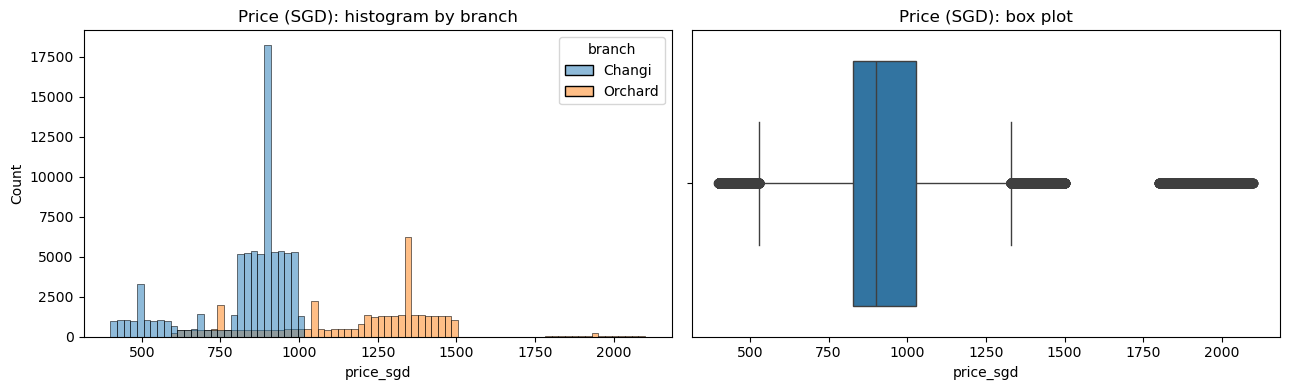

In [271]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x='price_sgd', hue='branch', bins=80, ax=axes[0])
axes[0].set_title('Price (SGD): histogram by branch')
sns.boxplot(data=df, x='price_sgd', ax=axes[1])
axes[1].set_title('Price (SGD): box plot')
plt.tight_layout()
plt.show()

### Findings: univariate analysis

**Categorical**
- `branch`: Changi takes two thirds of bookings (66%), Orchard one third.
- `booking_month` is almost uniform (8–9% each month). `arrival_month` and `checkout_month` are seasonal: they peak in July–August (about 11–12%) and are lowest in November–January (about 5–6%).
- `country`: China (41%) and Indonesia (22%) dominate; Singapore and Malaysia are only about 3% each.
- `first_time` is very imbalanced: 97% Yes, 3% No.
- `room`: King is 72% of bookings; President Suite is rare (0.8%, 932 bookings).
- `platform`: Website 45%, Email 27%, Agent 18%, Phone 9%.
- All categories have hundreds of bookings or more, so none need grouping into "Other" for one-hot encoding.

**Numeric**
- `no_show`: mean 0.37, the 37% no-show rate seen in §5.
- `arrival_day` / `checkout_day`: spread evenly over 1–31 (median 16).
- `num_adults`: 1 or 2 (58% are 1). `num_children`: 0–3, median 1; 3 children is rare.

**Price (SGD)**
- Range 400–2,100, median 900, mean 950, mild right skew (0.59). 98% of prices are 426–1,496; above that are mostly President Suites.
- The histogram is a set of flat blocks, one per room/branch price band (§4.1), not a smooth curve. The tall spikes are the 24,881 missing prices filled with their group median (§4.2).
- The box plot flags President Suite prices as outliers, but they are real prices for a real room type, so keep them.

## 8. Feature engineering

### 8.1 Length of stay

**What:** Compute the number of nights from the arrival date to the checkout date.

**Why:** Longer stays are bigger commitments, so they may be less likely to be no-shows (or more, if they are speculative bookings). Neither date column says this on its own.

**How:** The data has months and days but no year, so assume one:
- Use **2000**, a leap year, because some bookings arrive on 29 February, which does not exist in other years.
- If the checkout month comes before the arrival month (e.g. arrive 30 December, leave 2 January), the stay crosses the new year, so the checkout gets year 2001.

In [272]:
month_to_num = {month: number for number, month in enumerate(month_order, start=1)}
arrival_month_num = df['arrival_month'].map(month_to_num)
checkout_month_num = df['checkout_month'].map(month_to_num)

arrival_date = pd.to_datetime(
    pd.DataFrame({'year': 2000, 'month': arrival_month_num, 'day': df['arrival_day']}), errors='coerce',
)
crosses_new_year = checkout_month_num < arrival_month_num
checkout_date = pd.to_datetime(
    pd.DataFrame({'year': 2000 + crosses_new_year.astype(int), 'month': checkout_month_num, 'day': df['checkout_day']}),
    errors='coerce',
)
assert arrival_date.notna().all() and checkout_date.notna().all(), 'Some dates could not be parsed'

df['stay_nights'] = (checkout_date - arrival_date).dt.days
assert (df['stay_nights'] >= 1).all(), 'Some stays are zero or negative'
print('Stays crossing the new year:', crosses_new_year.sum())
df['stay_nights'].describe().round(2)

Stays crossing the new year: 792


count    119390.00
mean          2.11
std           2.17
min           1.00
25%           1.00
50%           2.00
75%           2.00
max          64.00
Name: stay_nights, dtype: float64

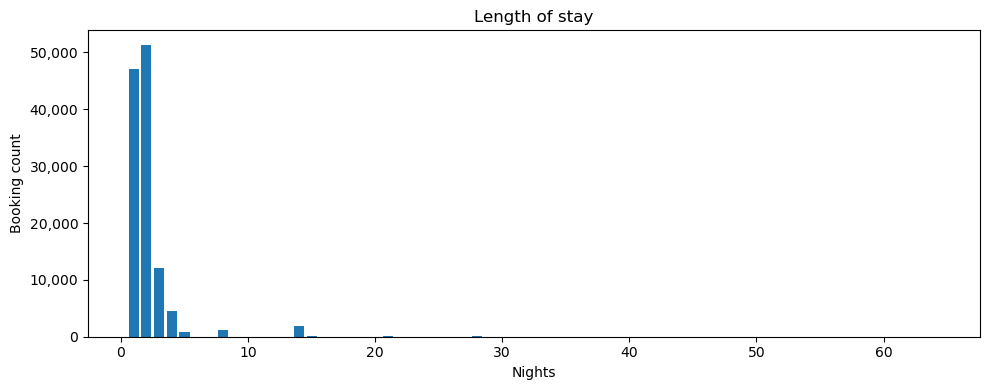

In [273]:
fig, ax = plt.subplots(figsize=(10, 4))
stay_counts = df['stay_nights'].value_counts().sort_index()
ax.bar(stay_counts.index, stay_counts.values)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))
ax.set_xlabel('Nights')
ax.set_ylabel('Booking count')
ax.set_title('Length of stay')
plt.tight_layout()
plt.show()

### 8.2 Booking lead time

**What:** Compute how many months ahead of arrival each booking was made: arrival month minus booking month.

**Why:** Bookings made far in advance give guests more time to change their plans, so lead time is often one of the strongest no-show predictors.

**How:** Take the difference modulo 12, so a booking in November for an arrival in June counts as 7 months ahead, not −5.

**Limitation:** without a year, a booking in the same month as arrival gives 0, but so would a booking made exactly 12 months ahead. Lead time is therefore 0–11 months, and anything a year or more ahead wraps around.

In [274]:
booking_month_num = df['booking_month'].map(month_to_num)
df['lead_time_months'] = (arrival_month_num - booking_month_num) % 12

lead_counts = df['lead_time_months'].value_counts().sort_index()
pd.DataFrame({'count': lead_counts, 'pct': (lead_counts / len(df) * 100).round(2)})

,count,pct
lead_time_months,,
0,14830,12.42
1,11822,9.90
2,10272,8.60
3,9897,8.29
4,10128,8.48
5,9428,7.90
6,9120,7.64
7,9127,7.64
8,9389,7.86


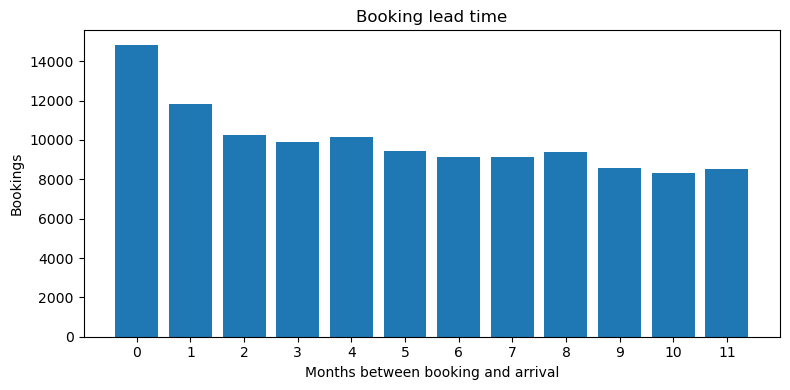

In [275]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(lead_counts.index, lead_counts.values)
ax.set_xticks(range(12))
ax.set_xlabel('Months between booking and arrival')
ax.set_ylabel('Bookings')
ax.set_title('Booking lead time')
plt.tight_layout()
plt.show()

### 8.3 Price per person

**What:** Divide the room price by the number of guests (adults + children).

**Why:** The same price means something different for one guest than for a family of four. Price per person measures the cost to each guest, which may relate to how committed they are to the booking.

In [276]:
df['num_guests'] = df['num_adults'] + df['num_children']
df['price_per_person'] = df['price_sgd'] / df['num_guests']

print(df['num_guests'].value_counts().sort_index().to_string())
print('Null or infinite price_per_person:', (~np.isfinite(df['price_per_person'])).sum())
df['price_per_person'].describe().round(2)

num_guests
1    27019
2    45299
3    32329
4    14602
5      141
Null or infinite price_per_person: 0


count    119390.00
mean        494.79
std         266.85
min         134.30
25%         300.14
50%         436.21
75%         594.96
max        2092.33
Name: price_per_person, dtype: float64

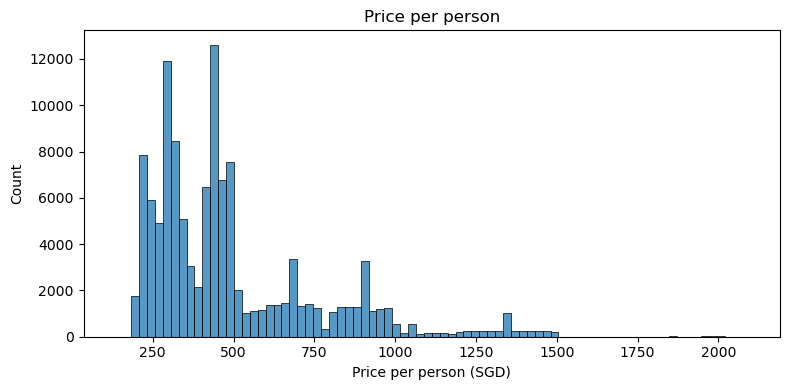

In [277]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x='price_per_person', bins=80, ax=ax)
ax.set_xlabel('Price per person (SGD)')
ax.set_title('Price per person')
plt.tight_layout()
plt.show()

### 8.4 Summary of engineered features

| Feature | Formula | Range | Notes |
|---|---|---|---|
| `stay_nights` | checkout date − arrival date (year 2000; checkout in 2001 if it crosses the new year) | 1–64, median 2 | Mostly 1–3 nights (92%); long tail up to 64. 792 stays cross the new year. |
| `lead_time_months` | (arrival month − booking month) mod 12 | 0–11 | 12% book in the arrival month, then a slow decline. A booking 12+ months ahead wraps around to 0–11. |
| `num_guests` | `num_adults` + `num_children` | 1–5 | 2 guests most common; 5 is rare (141). |
| `price_per_person` | `price_sgd` / `num_guests` | 134–2,092, median 436 | Right-skewed; the high values are solo guests in expensive rooms. |

> **Note for the pipeline:** these features use only values from the same row, so in `src/data_preparation.py` they can be computed on the whole dataset before the train/test split. Their relationship with `no_show` is analysed next.

## 9. Bivariate analysis: each feature vs `no_show`

**What:** Measure how strongly each feature is related to the target, one feature at a time.

**Why:** This shows which features are likely to help the model and which add nothing. How features relate to *each other* is covered in §10.

**How:**
- **Categorical features:** compare the no-show rate across categories, and test the relationship with a **chi-square test**. **Cramér's V** gives its strength from 0 (none) to 1 (perfect).
- **Numeric features:** plot the no-show rate across values, and compute **Spearman's ρ** with the target. Spearman measures any steadily rising or falling trend, not just a straight line.
- **All features:** rank them on one scale with **mutual information**, which also picks up patterns that go up and then down.

With 119,390 rows, even tiny differences are "statistically significant" (p < 0.05). So the p-value only tells us whether a relationship exists at all; the **effect size** (V, ρ, mutual information, and how far the no-show rates differ) tells us whether it matters.

In [278]:
from scipy.stats import chi2_contingency, spearmanr
from sklearn.feature_selection import mutual_info_classif

overall_rate = df['no_show'].mean()
print(f'Overall no-show rate: {overall_rate:.3f}')

Overall no-show rate: 0.370


### 9.1 Categorical features

**What:** For each categorical feature, run a chi-square test of independence against `no_show` and compute Cramér's V.

In [279]:
def cramers_v(table: pd.DataFrame) -> float:
    """Cramér's V effect size for a contingency table (0 = no association, 1 = perfect)."""
    chi2 = chi2_contingency(table)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))


cat_stats = []
for col in categorical_cols:
    table = pd.crosstab(df[col], df['no_show'])
    chi2, p_value, dof, _ = chi2_contingency(table)
    rates = df.groupby(col)['no_show'].mean()
    cat_stats.append({
        'feature': col, 'n_categories': table.shape[0], 'chi2': round(chi2, 1), 'p_value': p_value,
        'cramers_v': round(cramers_v(table), 3),
        'lowest_rate': f'{rates.idxmin()} ({rates.min():.0%})', 'highest_rate': f'{rates.idxmax()} ({rates.max():.0%})',
    })
cat_stats = pd.DataFrame(cat_stats).set_index('feature').sort_values('cramers_v', ascending=False)
cat_stats

,n_categories,chi2,p_value,cramers_v,lowest_rate,highest_rate
feature,,,,,,
country,7,14066.6,0.000000e+00,0.343,Japan (17%),China (57%)
branch,2,2224.9,0.000000e+00,0.137,Orchard (28%),Changi (42%)
first_time,2,857.4,1.784125e-188,0.085,No (14%),Yes (38%)
arrival_month,12,588.7,3.671823e-119,0.070,January (30%),June (41%)
room,4,563.2,9.516856e-122,0.069,Queen (32%),King (39%)
checkout_month,12,567.9,1.022712e-114,0.069,January (31%),June (42%)
booking_month,12,205.6,5.163566e-38,0.041,February (34%),June (41%)
platform,4,5.4,1.458861e-01,0.007,Phone (36%),Email (37%)


**What:** Plot the no-show rate for each category. The dashed line is the overall rate (37%).

**Why:** Bars far from the dashed line are the categories that carry information about no-shows.

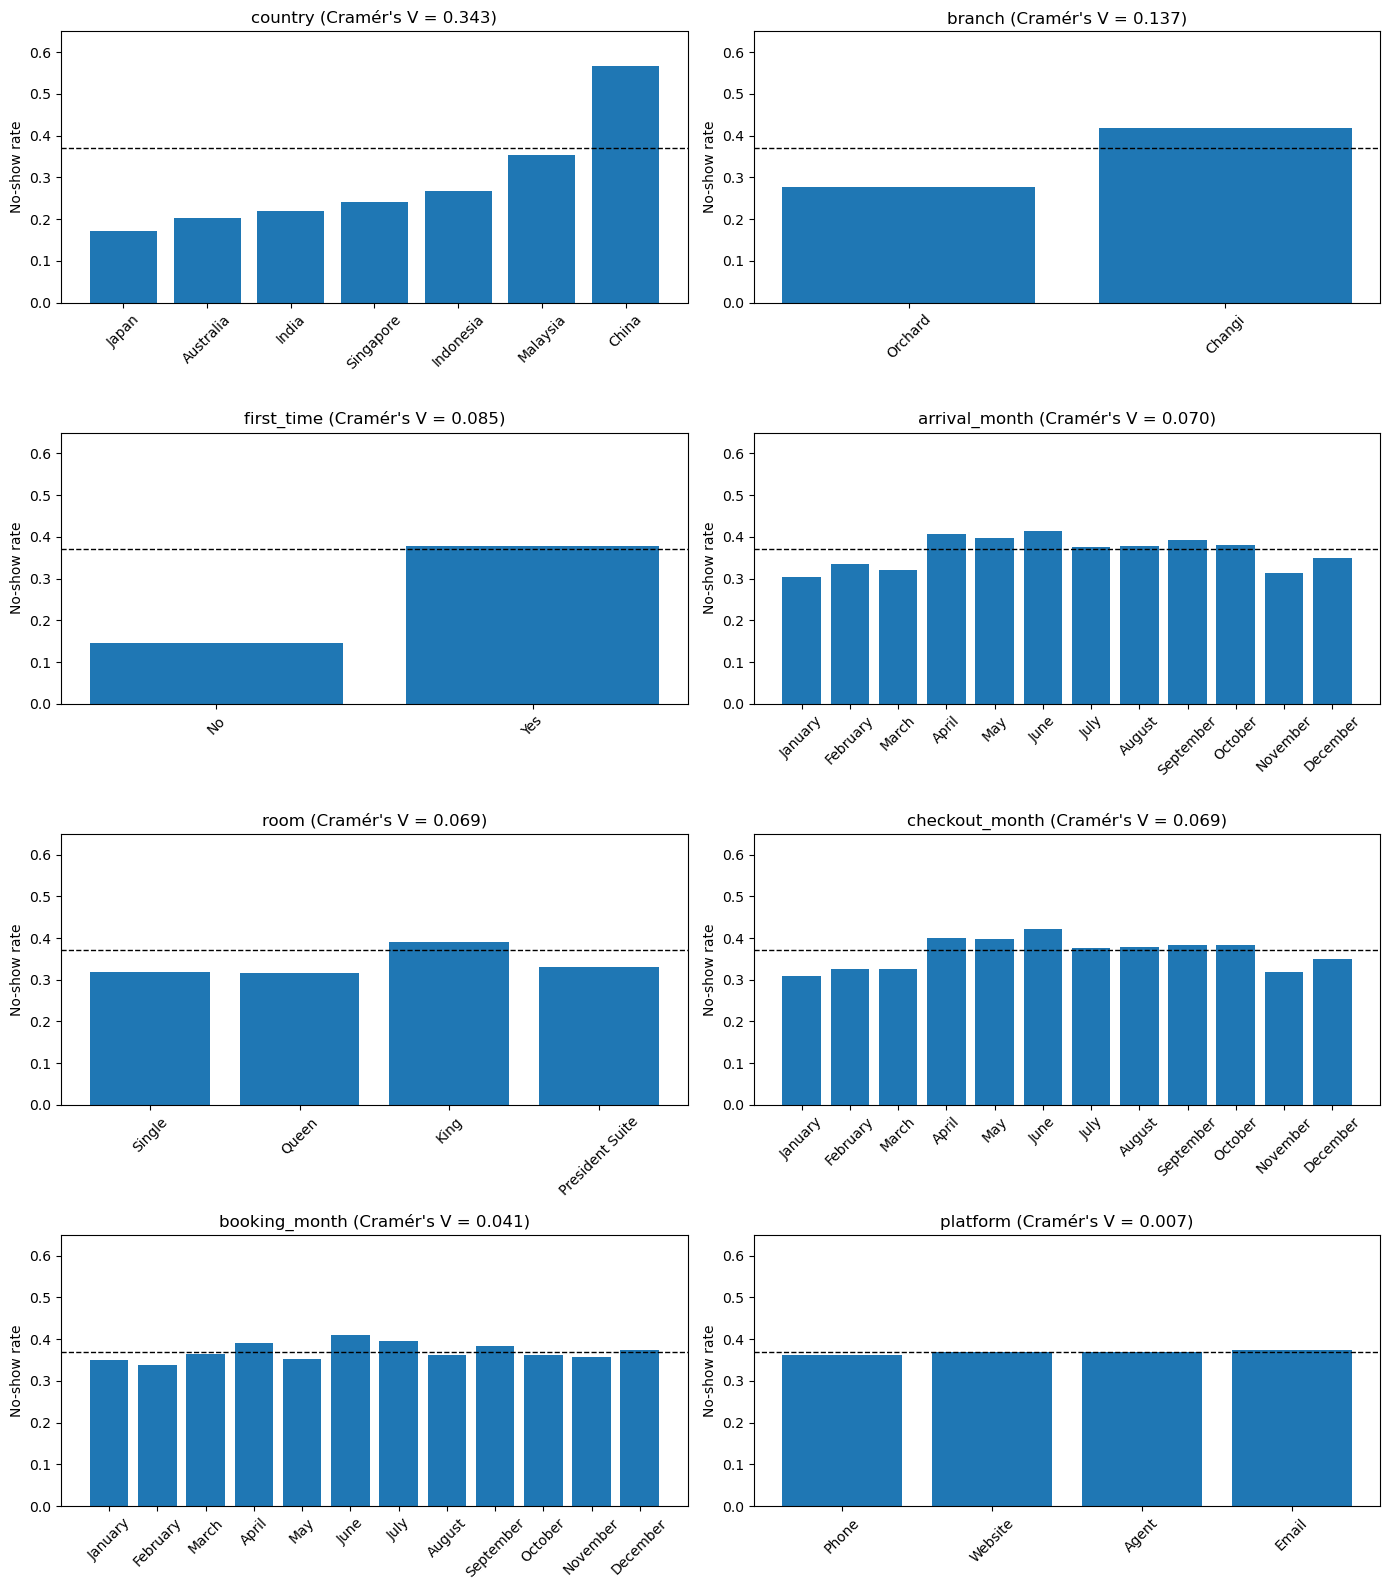

In [280]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for ax, col in zip(axes.flat, cat_stats.index):
    rates = df.groupby(col)['no_show'].mean()
    rates = rates.loc[category_order[col]] if col in category_order else rates.sort_values()
    ax.bar(rates.index, rates.values)
    ax.axhline(overall_rate, color='black', linestyle='--', linewidth=1)
    ax.set_title(f"{col} (Cramér's V = {cat_stats.loc[col, 'cramers_v']:.3f})")
    ax.set_ylabel('No-show rate')
    ax.set_ylim(0, 0.65)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

#### Findings: categorical features

- **`country` is by far the strongest feature** (V = 0.34). The no-show rate ranges from 17% for Japan to **57% for China**, the largest group (41% of bookings).
- **`branch`** is the next strongest (V = 0.14): Changi 42% vs Orchard 28%.
- **`first_time`** (V = 0.09): repeat guests rarely fail to show (14%) compared with first-timers (38%). Only 3% of guests are repeat guests, which keeps V moderate.
- **`arrival_month` / `checkout_month`** (V = 0.07): seasonal, lowest in November–January (about 31%) and highest in April–June (about 41%). The two columns tell almost the same story.
- **`room`** (V = 0.07): King rooms have a higher no-show rate (39%) than the other rooms (32–33%).
- **`booking_month`** is weak (V = 0.04).
- **`platform` has no relationship with no-shows** (V = 0.007, p = 0.15). It is the only feature that is not even statistically significant: every platform is at 36–38%.

### 9.2 Country, controlled for branch

**What:** Compare no-show rates by country within each branch.

**Why:** Countries are not spread evenly across the branches, and Changi has a higher no-show rate. If one country books mostly at Changi, its high rate might just reflect the branch. Splitting by branch checks whether the country effect holds on its own.

In [281]:
pd.crosstab(df['country'], df['branch'], values=df['no_show'], aggfunc='mean').round(3).sort_values('Changi')

branch,Changi,Orchard
country,,
Japan,0.183,0.118
India,0.240,0.167
Singapore,0.252,0.200
Australia,0.294,0.131
Indonesia,0.301,0.195
Malaysia,0.379,0.174
China,0.649,0.422


The country pattern holds in both branches. China has the highest rate at both Changi (65%) and Orchard (42%), and Japan the lowest. So country carries information beyond the branch mix, and both features are worth keeping.

### 9.3 Numeric features

**What:** Compute Spearman's ρ between each numeric feature and `no_show`, and compare the medians of the two classes.

In [282]:
numeric_features = ['lead_time_months', 'stay_nights', 'price_per_person', 'price_sgd', 'num_guests',
                    'num_children', 'num_adults', 'checkout_day', 'arrival_day']
num_stats = []
for col in numeric_features:
    rho, p_value = spearmanr(df[col], df['no_show'])
    medians = df.groupby('no_show')[col].median()
    num_stats.append({
        'feature': col, 'spearman_rho': round(rho, 3), 'p_value': p_value,
        'median_show': medians[0], 'median_no_show': medians[1],
    })
num_stats = pd.DataFrame(num_stats).set_index('feature')
num_stats = num_stats.reindex(num_stats['spearman_rho'].abs().sort_values(ascending=False).index)
num_stats

,spearman_rho,p_value,median_show,median_no_show
feature,,,,
lead_time_months,0.089,1.060138e-208,4.000000,5.000000
stay_nights,0.065,3.902087e-113,2.000000,2.000000
price_per_person,-0.052,4.845556e-73,442.670975,425.254925
price_sgd,-0.049,1.720075e-65,900.414400,900.414400
num_guests,0.023,5.162105e-16,2.000000,2.000000
num_children,0.018,1.993153e-10,1.000000,1.000000
checkout_day,-0.016,8.202792e-08,16.000000,16.000000
num_adults,0.015,5.370363e-07,1.000000,1.000000
arrival_day,-0.006,3.381828e-02,16.000000,16.000000


**What:** Plot the no-show rate across the values of each numeric feature.

**Why:** A single correlation can hide patterns that rise and then fall. The plots show the actual shape. Discrete features use each value; `stay_nights` is grouped into bins because long stays are rare; the two prices are split into 10 equal-sized groups (deciles).

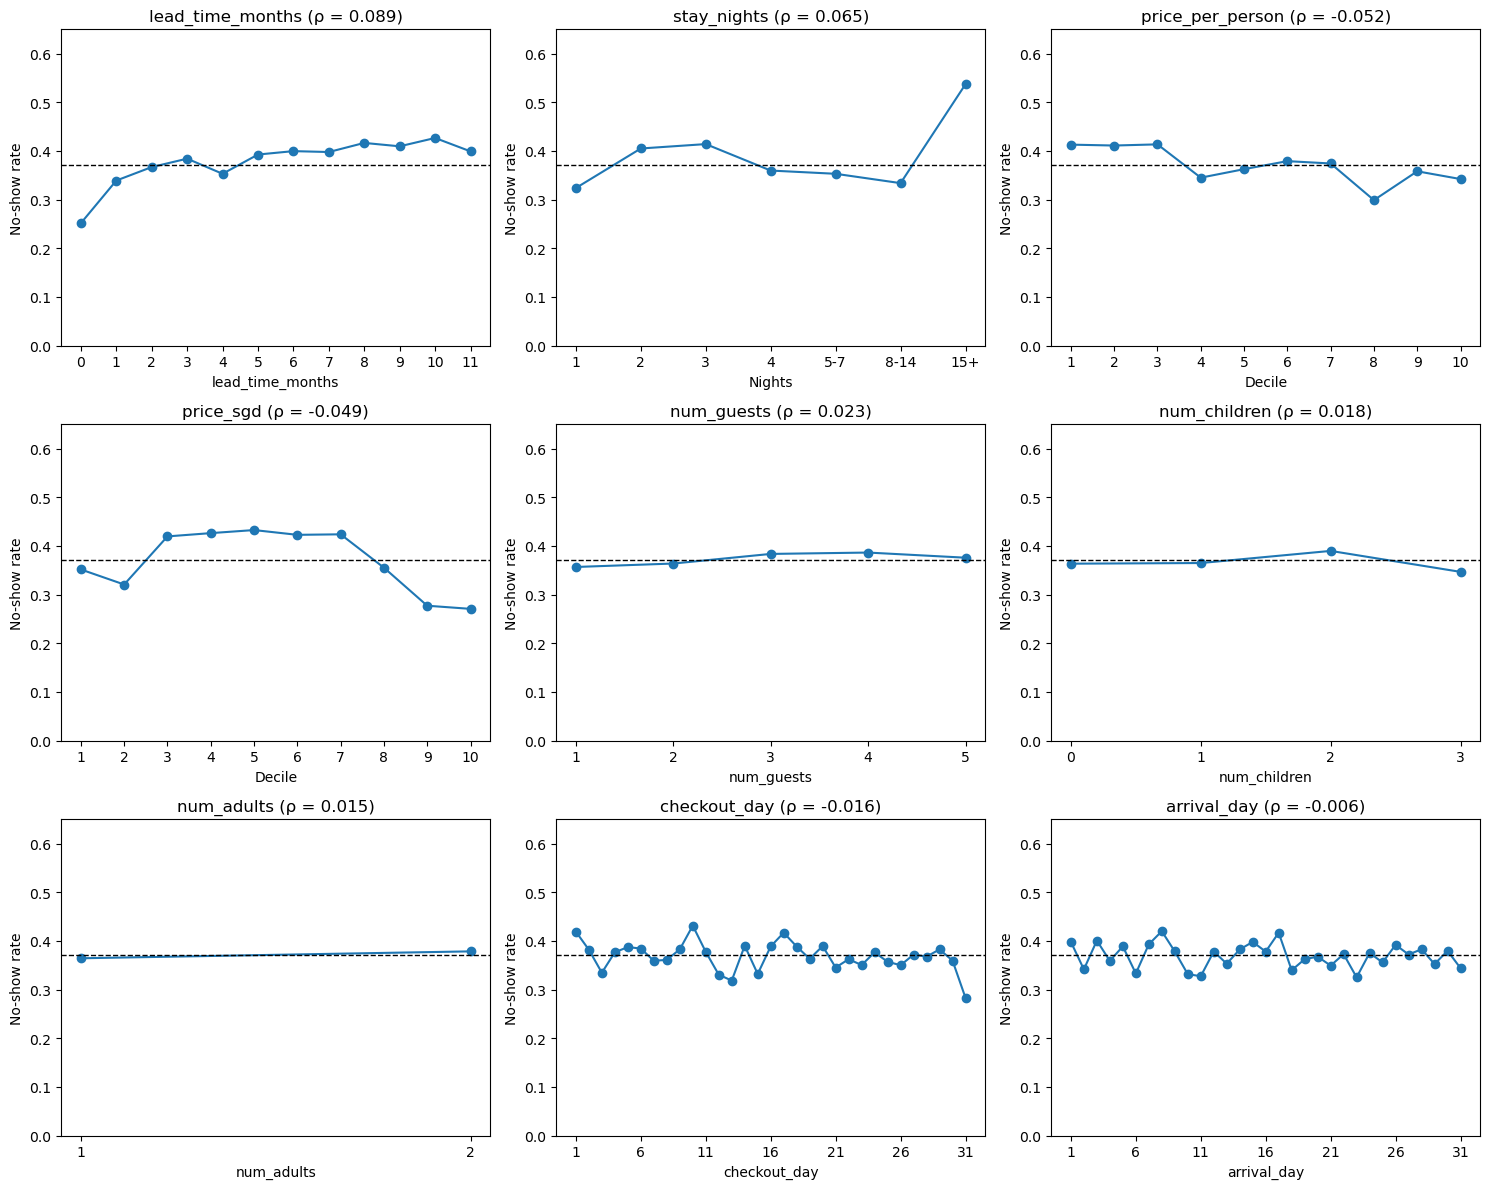

In [283]:
stay_bins = pd.cut(df['stay_nights'], bins=[0, 1, 2, 3, 4, 7, 14, 100], labels=['1', '2', '3', '4', '5-7', '8-14', '15+'])
grouped = {
    'lead_time_months': df['lead_time_months'],
    'stay_nights': stay_bins,
    'price_per_person': pd.qcut(df['price_per_person'], 10, labels=range(1, 11)),
    'price_sgd': pd.qcut(df['price_sgd'], 10, labels=range(1, 11)),
    'num_guests': df['num_guests'],
    'num_children': df['num_children'],
    'num_adults': df['num_adults'],
    'checkout_day': df['checkout_day'],
    'arrival_day': df['arrival_day'],
}
x_labels = {'price_per_person': 'Decile', 'price_sgd': 'Decile', 'stay_nights': 'Nights'}

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, (col, groups) in zip(axes.flat, grouped.items()):
    rates = df.groupby(groups, observed=True)['no_show'].mean()
    ax.plot(rates.index.astype(str), rates.values, marker='o')
    ax.axhline(overall_rate, color='black', linestyle='--', linewidth=1)
    ax.set_title(f"{col} (ρ = {num_stats.loc[col, 'spearman_rho']:.3f})")
    ax.set_xlabel(x_labels.get(col, col))
    ax.set_ylabel('No-show rate')
    ax.set_ylim(0, 0.65)
    if col.endswith('_day'):
        ax.set_xticks(ax.get_xticks()[::5])
plt.tight_layout()
plt.show()

In [284]:
df.groupby(stay_bins, observed=True)['no_show'].agg(['mean', 'size']).round(3)

,mean,size
stay_nights,,
1,0.324,47170
2,0.405,51332
3,0.414,12105
4,0.360,4481
5-7,0.353,844
8-14,0.334,3082
15+,0.537,376


#### Findings: numeric features

- **`lead_time_months` is the strongest numeric feature** (ρ = 0.09). Bookings made in the arrival month have a 25% no-show rate; it rises to about 40–43% for bookings made 8 or more months ahead. Guests who book far ahead have more time to change their plans.
- **`stay_nights`** (ρ = 0.07) does not follow a straight line: 1-night stays are at 32%, 2–3 nights at about 41%, then lower again for 4–14 nights. The 15+ night group is high (54%) but has only 376 bookings.
- **`price_sgd` / `price_per_person`** are weak (ρ ≈ −0.05), with a rise-and-fall pattern: the middle price deciles have the highest rates. §9.4 shows this comes from room and branch.
- **`num_adults`, `num_children`, `num_guests`** are very weak (ρ ≈ 0.02): all groups sit at 35–39%.
- **`arrival_day` / `checkout_day`** show no relationship: flat at about 37% across the month.

### 9.4 Price, controlled for branch and room

**What:** Compare no-show rates by room within each branch.

**Why:** Price is set by room and branch (§4.1). If the no-show rate differs by room and branch, the price pattern in §9.3 may just be a side effect of those two features.

In [285]:
pd.crosstab(df['room'], df['branch'], values=df['no_show'], aggfunc='mean').loc[room_order].round(3)

branch,Changi,Orchard
room,,
Single,0.352,0.263
Queen,0.344,0.299
King,0.435,0.273
President Suite,0.357,0.330


Changi King rooms have the highest no-show rate (44%), and they make up most of the middle price deciles. That explains the price peak in §9.3: price adds little once branch and room are known.

### 9.5 Overall ranking: mutual information

**What:** Compute the mutual information between each feature and `no_show`.

**Why:** Cramér's V and Spearman's ρ are on different scales and Spearman misses rise-and-fall patterns. Mutual information measures any kind of dependence, for categorical and numeric features alike, so it puts every feature on one scale. Categorical features are label-encoded for this; only the two price columns are treated as continuous.

In [286]:
mi_features = categorical_cols + numeric_features
X_mi = df[mi_features].copy()
for col in categorical_cols:
    X_mi[col] = X_mi[col].astype('category').cat.codes
continuous = ['price_sgd', 'price_per_person']
mi = mutual_info_classif(
    X_mi, df['no_show'], discrete_features=[col not in continuous for col in mi_features], random_state=42,
)

ranking = pd.DataFrame({'mutual_info': mi}, index=mi_features)
ranking['cramers_v_or_abs_rho'] = pd.concat([cat_stats['cramers_v'], num_stats['spearman_rho'].abs()])
ranking['type'] = ['categorical' if col in categorical_cols else 'numeric' for col in ranking.index]
ranking = ranking.sort_values('mutual_info', ascending=False)
ranking.round(4)

,mutual_info,cramers_v_or_abs_rho,type
country,0.0598,0.343,categorical
price_sgd,0.0105,0.049,numeric
branch,0.0095,0.137,categorical
price_per_person,0.0069,0.052,numeric
lead_time_months,0.0058,0.089,numeric
first_time,0.0041,0.085,categorical
stay_nights,0.0038,0.065,numeric
arrival_month,0.0025,0.070,categorical
checkout_month,0.0024,0.069,categorical
room,0.0024,0.069,categorical


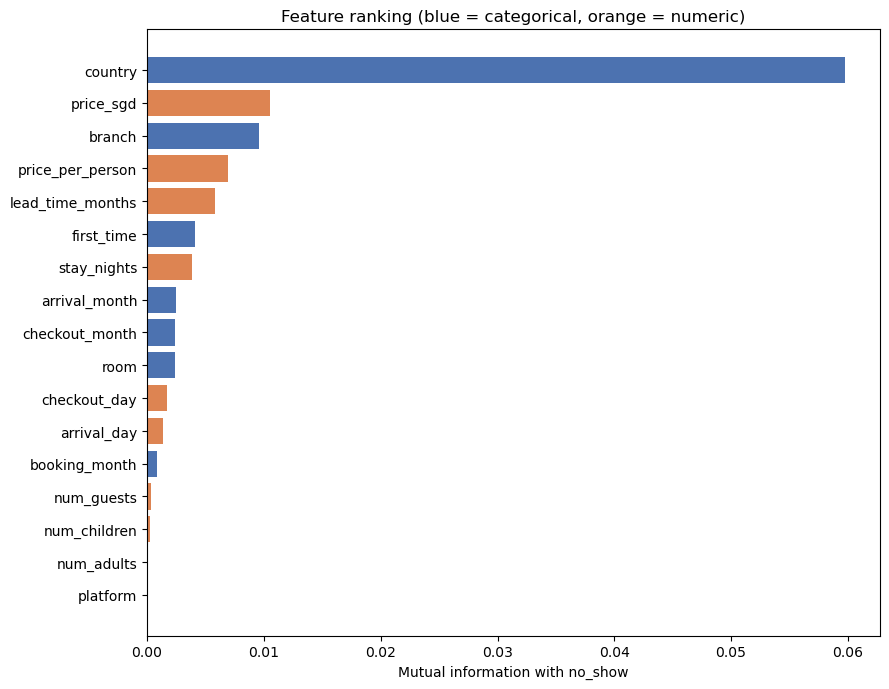

In [287]:
fig, ax = plt.subplots(figsize=(9, 7))
colors = ranking['type'].map({'categorical': '#4C72B0', 'numeric': '#DD8452'})
ax.barh(ranking.index[::-1], ranking['mutual_info'][::-1], color=colors[::-1])
ax.set_xlabel('Mutual information with no_show')
ax.set_title('Feature ranking (blue = categorical, orange = numeric)')
plt.tight_layout()
plt.show()

#### Findings: overall ranking

- **`country` is clearly first** on every measure; its mutual information is about 6× the next feature.
- **`price_sgd` ranks second by mutual information**, despite its weak Spearman ρ. Each room/branch combination has its own price band (§4.1), so price alone tells the model both the branch and the room. Mutual information picks this up because it is not limited to steady trends. It overlaps with `branch` and `room` rather than adding new information (§9.4).
- `branch`, `lead_time_months`, `first_time`, `stay_nights`, `arrival_month` and `room` form the next group.
- `arrival_day` / `checkout_day` score slightly above `booking_month` here. Mutual information is biased upwards for features with many values (31 days), and their no-show rates are flat (§9.3), so this is noise.
- `num_adults`, `num_children`, `num_guests` and `platform` are close to zero.

### 9.6 Summary: feature strength vs `no_show`

| Feature | Strength | No-show rate range |
|---|---|---|
| `country` | **Strong** (V = 0.34) | 17% (Japan) – 57% (China) |
| `branch` | Strong (V = 0.14) | 28% (Orchard) – 42% (Changi) |
| `lead_time_months` | Moderate (ρ = 0.09) | 25% (same month) – 43% |
| `first_time` | Moderate (V = 0.09) | 14% (repeat) – 38% (first time) |
| `arrival_month` | Moderate (V = 0.07) | 30% – 41% |
| `checkout_month` | Moderate (V = 0.07) | 31% – 42% |
| `room` | Moderate (V = 0.07) | 32% – 39% (King) |
| `stay_nights` | Moderate (ρ = 0.07), not a straight line | 32% – 41% |
| `price_sgd`, `price_per_person` | Weak trend (ρ ≈ −0.05), but `price_sgd` is 2nd by mutual information | mostly explained by room and branch (§9.4) |
| `booking_month` | Weak (V = 0.04) | 34% – 41% |
| `num_adults`, `num_children`, `num_guests` | Very weak (ρ ≈ 0.02) | 35% – 39% |
| `arrival_day`, `checkout_day` | None (ρ ≈ −0.01) | flat at 37% |
| `platform` | **None** (V = 0.007, p = 0.15) | 36% – 38% |

**Takeaways**
- Who the guest is (`country`, `first_time`) and where and when they stay (`branch`, `arrival_month`, `lead_time_months`) matter most. How they booked (`platform`) and the exact day of the month do not matter.
- Every feature is weak to moderate on its own, so the model will need to combine them. Tree ensembles (Random Forest, Gradient Boosting) can also pick up the rise-and-fall patterns in stay length and price.
- Some of these features carry the same information as each other. §10 checks this and makes the final feature selection.

## 10. Correlation analysis and final feature selection

**What:** Measure how strongly the features are related to **each other**, then choose the final features for the model.

**Why:** Two features that carry the same information add little to a model, make it slower, and split the credit between them so feature importances become harder to read. Linear models can also become unstable when features are combinations of each other.

**How:** one measure per pair type, each on a 0–1 scale (for Spearman, the absolute value):

| Pair | Measure |
|---|---|
| numeric ↔ numeric | Spearman's ρ |
| categorical ↔ categorical | Cramér's V (reusing `cramers_v()` from §9.1) |
| categorical ↔ numeric | Correlation ratio η: how much of a numeric feature's variation is explained by the categories |
| all numeric features together | Variance inflation factor (VIF): catches a feature that is a *combination* of others |

A pair is treated as redundant if its association is **0.7 or higher**, or a feature's VIF is above 5.

### 10.1 Numeric ↔ numeric

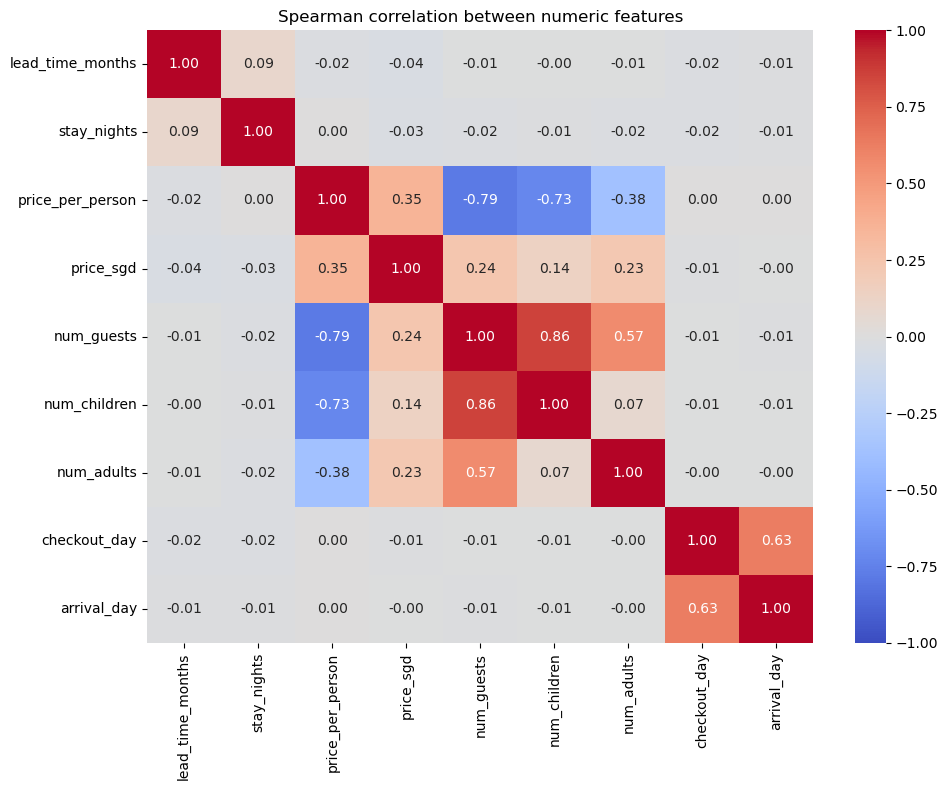

In [288]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df[numeric_features].corr(method='spearman'), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Spearman correlation between numeric features')
plt.tight_layout()
plt.show()

- `num_guests` is built from `num_children` (ρ = 0.86) and `num_adults` (0.57), and `price_per_person` is built from `num_guests` (−0.79) and `price_sgd` (0.35). These overlaps are expected for engineered features.
- `arrival_day` and `checkout_day` are correlated (0.63) because most stays are short.

### 10.2 Categorical ↔ categorical

**What:** Cramér's V for every pair of categorical features.

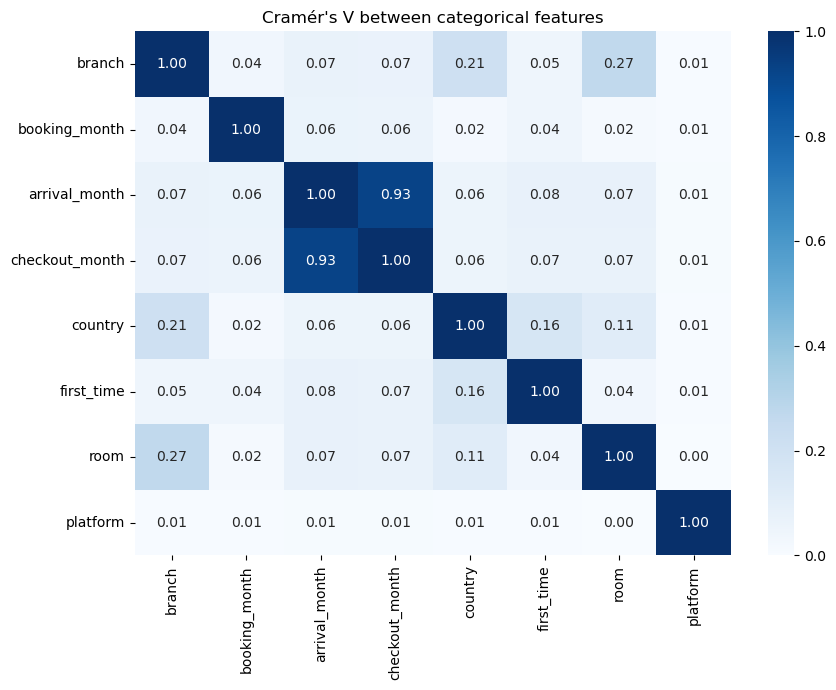

arrival_month == checkout_month: 93.0% of bookings


In [289]:
cat_assoc = pd.DataFrame(
    [[cramers_v(pd.crosstab(df[a], df[b])) for b in categorical_cols] for a in categorical_cols],
    index=categorical_cols, columns=categorical_cols,
)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cat_assoc, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax)
ax.set_title("Cramér's V between categorical features")
plt.tight_layout()
plt.show()

print(f"arrival_month == checkout_month: {(df['arrival_month'] == df['checkout_month']).mean():.1%} of bookings")

- **`arrival_month` ↔ `checkout_month`: V = 0.93.** They are the same month for 93% of bookings, so they are redundant. Keep `arrival_month`, which is known when the booking is made and is slightly stronger against the target.
- Every other pair is weak: `room` ↔ `branch` 0.27, `country` ↔ `branch` 0.21, `country` ↔ `first_time` 0.16.
- `platform` is unrelated to every other feature (V ≈ 0.01), as well as to the target.

### 10.3 Categorical ↔ numeric

**What:** The correlation ratio η for every categorical / numeric pair. η² is the share of the numeric feature's variance explained by the category means, so η = 0 means the categories have the same average and η = 1 means the category fully determines the value.

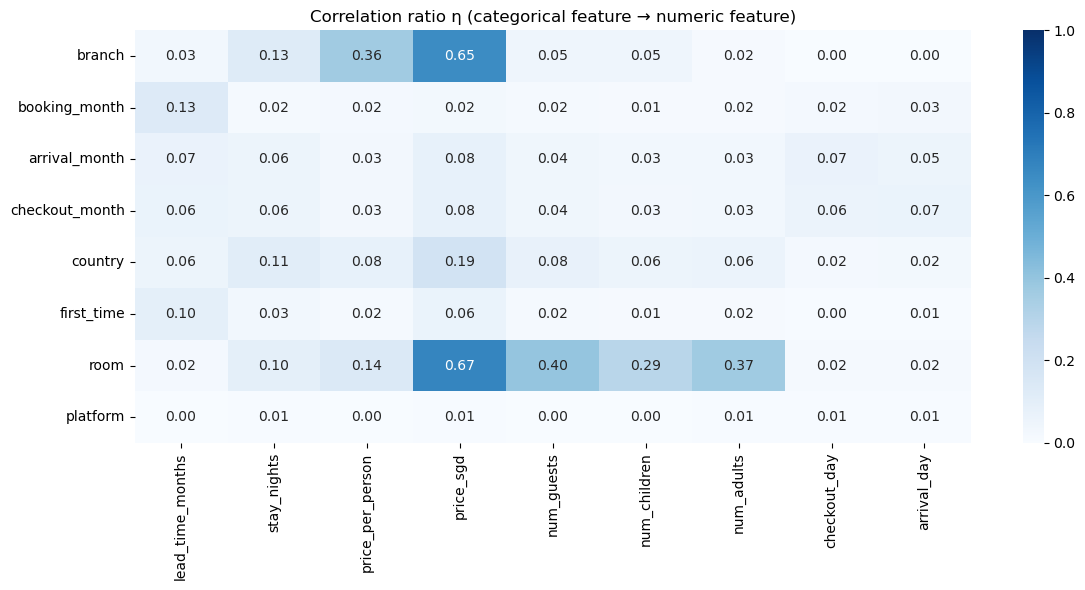

In [290]:
def correlation_ratio(categories: pd.Series, values: pd.Series) -> float:
    """Correlation ratio η: how much of a numeric variable's variation is explained by a categorical one."""
    group_means = values.groupby(categories).transform('mean')
    between = ((group_means - values.mean()) ** 2).sum()
    total = ((values - values.mean()) ** 2).sum()
    return np.sqrt(between / total)


cat_num_assoc = pd.DataFrame(
    [[correlation_ratio(df[c], df[n]) for n in numeric_features] for c in categorical_cols],
    index=categorical_cols, columns=numeric_features,
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(cat_num_assoc, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax)
ax.set_title('Correlation ratio η (categorical feature → numeric feature)')
plt.tight_layout()
plt.show()

`price_sgd` is linked to both `room` and `branch`. Check how much of price the two explain **together**.

In [291]:
room_branch_mean = df.groupby(['branch', 'room'])['price_sgd'].transform('mean')
r2 = 1 - ((df['price_sgd'] - room_branch_mean) ** 2).sum() / ((df['price_sgd'] - df['price_sgd'].mean()) ** 2).sum()
print(f'Share of price_sgd variance explained by branch × room: {r2:.1%}')

Share of price_sgd variance explained by branch × room: 94.7%


- **`price_sgd`** has η = 0.67 with `room` and 0.65 with `branch`, and the two together explain about **95%** of its variance. Price is therefore mostly a combination of room and branch. The remaining 5% is the variation *within* each price band, which is why price still ranked high by mutual information (§9.5).
- `room` ↔ `num_guests` (0.40): bigger rooms hold more guests, as expected. `branch` ↔ `price_per_person` (0.36) follows from Orchard's higher prices.
- All other pairs are below 0.2.

### 10.4 Multicollinearity (VIF)

**What:** For each numeric feature, regress it on all the other numeric features and compute VIF = 1 / (1 − R²).

**Why:** Pairwise correlations miss a feature that is a *combination* of several others, e.g. `num_guests = num_adults + num_children`. VIF = 1 means no overlap; above 5 is a common warning level; infinite means the feature is an exact combination of the others.

In [292]:
def vif(features: list) -> pd.Series:
    """Variance inflation factor of each feature, regressed on the others with least squares."""
    X = df[features].astype(float)
    result = {}
    for col in features:
        others = np.column_stack([np.ones(len(X)), X.drop(columns=col).values])
        coef, *_ = np.linalg.lstsq(others, X[col].values, rcond=None)
        residual = X[col].values - others @ coef
        r2 = 1 - (residual ** 2).sum() / ((X[col] - X[col].mean()) ** 2).sum()
        result[col] = np.inf if r2 > 1 - 1e-9 else 1 / (1 - r2)
    return pd.Series(result, name='VIF').round(2)


vif(numeric_features).sort_values(ascending=False)

num_guests           inf
num_adults           inf
num_children         inf
price_per_person    5.70
price_sgd           2.91
arrival_day         1.65
checkout_day        1.65
stay_nights         1.01
lead_time_months    1.00
Name: VIF, dtype: float64

- `num_guests`, `num_adults` and `num_children` have **infinite VIF**, because `num_guests` is exactly the sum of the other two. Only one representation should be kept.
- `price_per_person` (VIF about 6) is built from price and the guest counts.
- The other features are close to 1.

Check the VIF again after removing `num_guests` and `price_per_person`:

In [293]:
final_numeric_features = ['lead_time_months', 'stay_nights', 'price_sgd', 'num_adults', 'num_children']
vif(final_numeric_features)

lead_time_months    1.00
stay_nights         1.00
price_sgd           1.08
num_adults          1.05
num_children        1.03
Name: VIF, dtype: float64

All VIFs are close to 1, so the remaining numeric features carry separate information.

### 10.5 Final feature selection

Combining the target analysis (§9) and the correlation analysis above:

**Keep (10 features)**

| Feature | Type | Reason |
|---|---|---|
| `country` | nominal | strongest predictor (V = 0.34); holds within each branch (§9.2) |
| `branch` | nominal | strong (V = 0.14); only weakly related to country (V = 0.21) |
| `first_time` | nominal (binary) | moderate (V = 0.09) |
| `arrival_month` | nominal | moderate, seasonal (V = 0.07) |
| `room` | ordered (Single < Queen < King < President Suite), one-hot encoded | moderate (V = 0.07): King rooms have more no-shows. One-hot because the no-show rate does not follow the room order (King peaks at Changi, §9.4), and `price_sgd` already carries the ordering |
| `lead_time_months` | numeric | strongest numeric feature (ρ = 0.09) |
| `stay_nights` | numeric | moderate (ρ = 0.07), not a straight line |
| `price_sgd` | numeric | 2nd by mutual information. Mostly explained by branch × room, but adds the variation within each band; VIF ≈ 1 |
| `num_adults`, `num_children` | numeric | weak but separate (VIF ≈ 1); kept instead of their sum `num_guests` |

**Drop**

| Feature | Reason |
|---|---|
| `checkout_month` | Redundant with `arrival_month` (V = 0.93) |
| `num_guests` | Exactly `num_adults` + `num_children` (infinite VIF) |
| `price_per_person` | Built from price and guest counts (VIF ≈ 6), and weaker than `price_sgd` |
| `booking_month` | Weak (V = 0.04), and its useful information is already in `lead_time_months` |
| `arrival_day`, `checkout_day` | No relationship with `no_show` (§9.3) |
| `platform` | No relationship with `no_show` (p = 0.15) or with any other feature |
| `booking_id` | Identifier only |

In [294]:
final_nominal_features = ['country', 'branch', 'first_time', 'arrival_month', 'room']
target = 'no_show'
final_features = final_nominal_features + final_numeric_features

print(f'{len(final_features)} features:', final_features)
df[final_features + [target]].info()

10 features: ['country', 'branch', 'first_time', 'arrival_month', 'room', 'lead_time_months', 'stay_nights', 'price_sgd', 'num_adults', 'num_children']
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   country           119390 non-null  str    
 1   branch            119390 non-null  str    
 2   first_time        119390 non-null  str    
 3   arrival_month     119390 non-null  str    
 4   room              119390 non-null  str    
 5   lead_time_months  119390 non-null  int64  
 6   stay_nights       119390 non-null  int64  
 7   price_sgd         119390 non-null  float64
 8   num_adults        119390 non-null  int64  
 9   num_children      119390 non-null  int64  
 10  no_show           119390 non-null  int64  
dtypes: float64(1), int64(5), str(5)
memory usage: 10.0 MB


**What:** Confirm that no pair of final features is still redundant (association ≥ 0.7).

In [295]:
pair_checks = []
for i, a in enumerate(final_features):
    for b in final_features[i + 1:]:
        if a in final_nominal_features and b in final_nominal_features:
            value, measure = cramers_v(pd.crosstab(df[a], df[b])), "Cramér's V"
        elif a in final_numeric_features and b in final_numeric_features:
            value, measure = abs(spearmanr(df[a], df[b])[0]), '|Spearman ρ|'
        else:
            cat_col, num_col = (a, b) if a in final_nominal_features else (b, a)
            value, measure = correlation_ratio(df[cat_col], df[num_col]), 'η'
        pair_checks.append({'feature_a': a, 'feature_b': b, 'measure': measure, 'association': round(value, 3)})

pair_checks = pd.DataFrame(pair_checks).sort_values('association', ascending=False)
print('Pairs at or above 0.7:', (pair_checks['association'] >= 0.7).sum())
pair_checks.head(5)

Pairs at or above 0.7: 0


,feature_a,feature_b,measure,association
32,room,price_sgd,η,0.672
14,branch,price_sgd,η,0.647
33,room,num_adults,η,0.370
34,room,num_children,η,0.293
11,branch,room,Cramér's V,0.268


No remaining pair reaches 0.7. The strongest overlaps are `price_sgd` with `room` and with `branch` (η ≈ 0.65–0.67), which we keep on purpose (§10.3).

> **Note for the pipeline:** these lists map directly onto `src/config.yaml`:
> - `nominal_features`: `country`, `branch`, `first_time`, `arrival_month`, `room`, all one-hot encoded. `arrival_month` is one-hot rather than a number because its seasonal pattern rises and falls (§9.1). `room` is one-hot for the same reason: its categories are ordered, but the no-show rate is not (King peaks at Changi, §9.4).
> - `numeric_features`: `lead_time_months`, `stay_nights`, `price_sgd`, `num_adults`, `num_children`, scaled for the linear and KNN models.
> - The cleaning (§6), missing-value fills (§4.2–4.3) and engineered features (§8) must be reproduced in `src/data_preparation.py`, with the fills learned from the training split only.